# Energy in 50–500 Hz, as a fraction of the whole

Twelve spring and twelve winter `df20` recordings from `/mnt/sda/SiteH`, one file from each selected year, seed 0. Spring is March–May and winter is December–February, taken from the `YYMMDD` stamp in the file name. Each file is 16-bit mono at 10 kHz.

For every 600-second segment, the plotted value is the energy in 50–500 Hz divided by the energy of the unfiltered segment. A ratio of 1 means all of the segment's energy is inside that band. The last segment is shorter when the file length is not a multiple of 600 seconds.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

here = Path("/home/yfreund/projects/panMP_whales/pre_processing/results")
spring = pd.read_csv(here / "segments.csv")
winter = pd.read_csv(here / "segments_winter.csv")
spring["season"] = "spring"
winter["season"] = "winter"
df = pd.concat([spring, winter], ignore_index=True)
df["ratio"] = (df["band_energy"] / df["overall_energy"]).where(df["overall_energy"] > 0, 0.0)
df["hours"] = df["start_sec"] / 3600.0

summary = (
    df.groupby(["season", "year", "site", "filename"], as_index=False)
    .agg(
        segments=("ratio", "size"),
        hours=("hours", "max"),
        median_ratio=("ratio", "median"),
        p95_ratio=("ratio", lambda s: s.quantile(0.95)),
    )
    .sort_values(["season", "year"])
)
print(f"{len(df)} segments from {df.groupby(['season', 'filename']).ngroups} files")
summary


3088 segments from 24 files


,season,year,site,filename,segments,hours,median_ratio,p95_ratio
0,spring,2009,SOCAL32H,SOCAL32H_DL26_090415_091506.df20.x.wav,135,22.333333,1.280335e-01,1.579008e-01
1,spring,2011,SOCAL41H,SOCAL41H_DL45_110310_232730.df20.x.wav,135,22.333333,3.178930e-01,8.756124e-01
2,spring,2012,SOCAL46H,SOCAL46H_DL76_120415_051010.df20.x.wav,79,13.000000,1.680783e-01,1.820037e-01
3,spring,2013,SOCAL48H,SOCAL48H_DL17_130413_065736.df20.x.wav,79,13.000000,9.977803e-02,2.454400e-01
4,spring,2014,SOCAL52H,SOCAL52H_DL81_140417_005500.df20.x.wav,135,22.333333,1.427136e-01,4.715183e-01
5,spring,2017,SOCAL_H_61,SOCAL_H_61_170504_092502_df20.x.wav,131,21.666667,1.902545e-03,9.241840e-03
6,spring,2018,SOCAL_H_64,SOCAL_H_64_180422_130000_df20.x.wav,132,21.833333,1.474853e-01,1.732911e-01
7,spring,2019,SOCAL_H_66,SOCAL_H_66_190425_145500_df20.x.wav,132,21.833333,4.644447e-04,1.144573e-03
8,spring,2020,SOCAL_H_68,SOCAL_H_68_200421_000845_df20.x.wav,132,21.833333,3.375622e-01,5.312259e-01
9,spring,2021,SOCAL_H_70,SOCAL_H_70_210417_121229_df20.x.wav,132,21.833333,4.048866e-01,6.143268e-01


## Ratio against time

Each panel is one recording. The vertical axis is the fraction of segment energy inside 50–500 Hz, on the same scale in every panel.


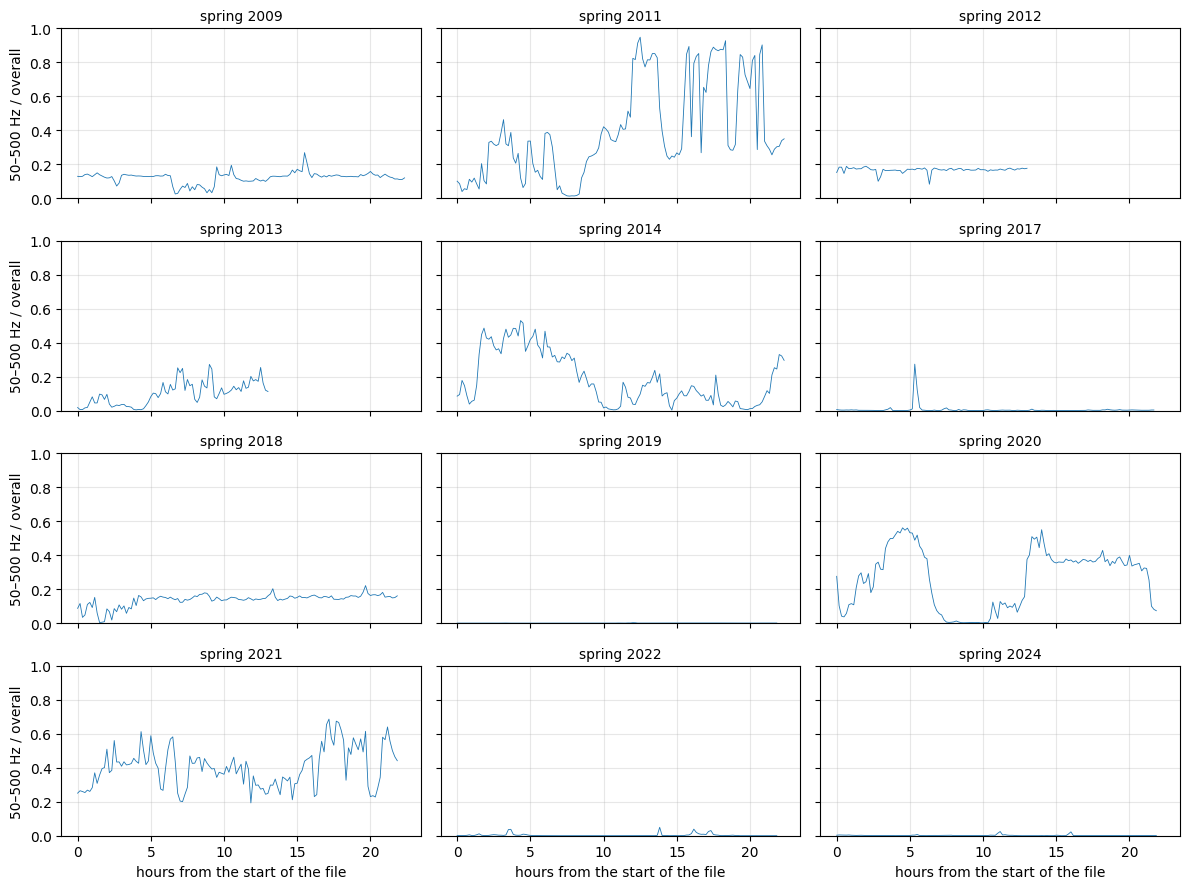

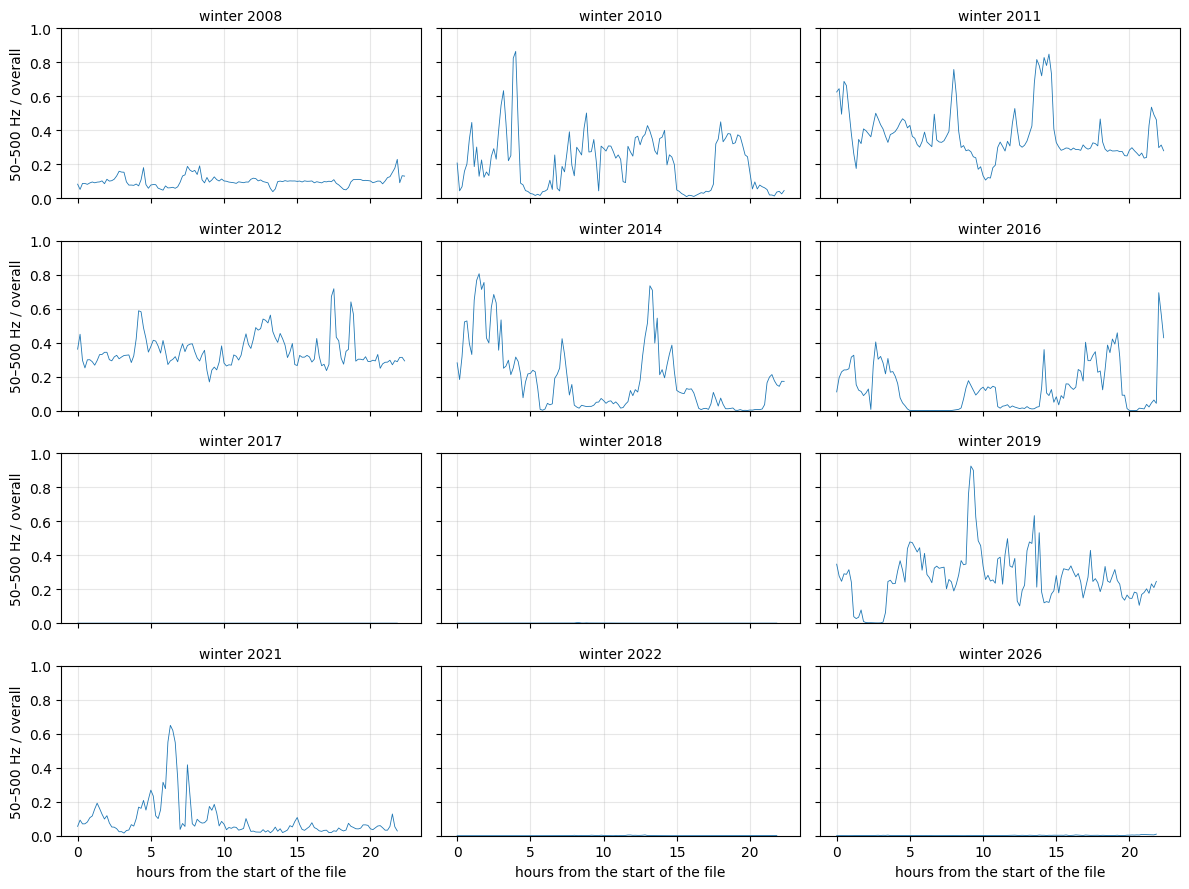

In [2]:
def time_figure(season):
    part = df[df["season"] == season]
    files = list(part.groupby(["year", "filename"], sort=True))
    fig, axes = plt.subplots(4, 3, figsize=(12, 9), sharex=True, sharey=True)
    for ax, ((year, name), g) in zip(axes.ravel(), files):
        ax.plot(g["hours"], g["ratio"], lw=0.6, color="C0")
        ax.set_title(f"{season} {year}", fontsize=10)
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("hours from the start of the file")
    for ax in axes[:, 0]:
        ax.set_ylabel("50–500 Hz / overall")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

time_figure("spring")
time_figure("winter")


## Distribution across segments

The horizontal axis is the base-10 logarithm of the ratio, so a segment at −1 has one tenth of its energy in 50–500 Hz and a segment at −3 has one thousandth. Values below 10⁻⁸ are drawn at the left edge. Each curve is one recording.


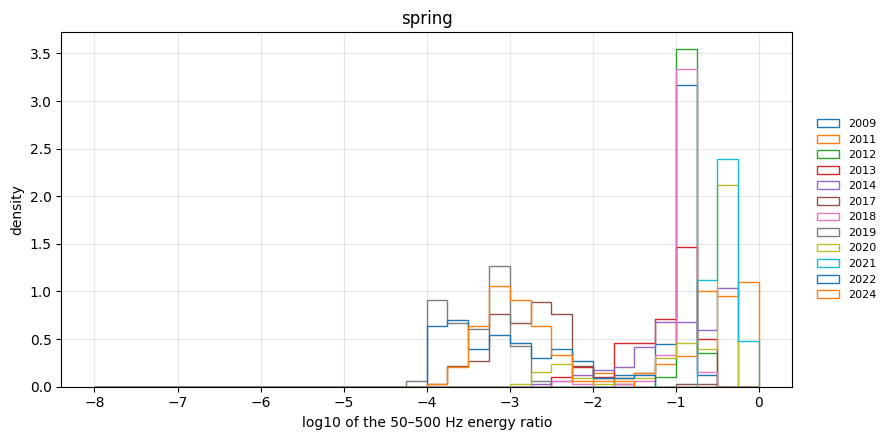

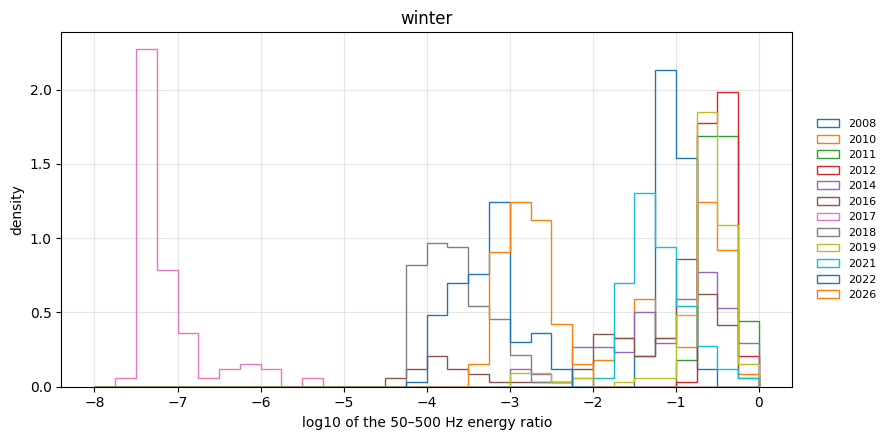

In [3]:
import numpy as np

def hist_figure(season):
    part = df[df["season"] == season]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bins = np.linspace(-8, 0, 33)
    for (year, name), g in part.groupby(["year", "filename"], sort=True):
        values = np.log10(g["ratio"].clip(lower=1e-8))
        ax.hist(values, bins=bins, histtype="step", density=True, label=str(year))
    ax.set_xlabel("log10 of the 50–500 Hz energy ratio")
    ax.set_ylabel("density")
    ax.set_title(season)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    plt.show()
    plt.close(fig)

hist_figure("spring")
hist_figure("winter")


Most recordings hold a steady fraction for the whole file, and that fraction falls into two groups.

In spring, the 2009, 2012, 2013, 2014, and 2018 files keep roughly 10–20% of their energy in 50–500 Hz. The 2011, 2020, and 2021 files sit higher, with medians from about 0.32 to 0.40, and the 2011 file repeatedly climbs above 0.8. The 2017, 2019, 2022, and 2024 files have medians below about 0.002.

Winter has the same split. The 2008, 2010, 2011, 2012, 2014, 2016, 2019, and 2021 files have medians from about 0.06 to 0.33. The 2018, 2022, and 2026 files stay near or below 0.002. The 2017 winter file is the extreme: its overall energy is large and nearly constant, and the 50–500 Hz share is about 10⁻⁷, so essentially none of that recording sits in the band.
